# Segmentación de Inmuebles en Arriendo con Machine Learning No Supervisado

**Estudiante:** Joan Schneider Beltrán Delgado
**Asignatura:** Introducción a Machine Learning, CADI, Universidad de Cundinamarca
**Docente:** Ing. Wilson Rojas Reales, PhD(c)
**Actividad:** R1-A3-S12 Informe de Trabajo – ML No Supervisado

Este notebook modifica y extiende el script de ejemplo entregado por el docente (`KMeansSegInmuebles.py`) para trabajar sobre el dataset real de 1000 inmuebles, aplicando cuatro técnicas: **K-Means**, **Clustering Jerárquico**, **PCA** y **SVD**.

## 1. Carga y exploración del dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

np.random.seed(42)

df = pd.read_excel("DATASET_INmuebles.xlsx")
print("Forma del dataset:", df.shape)
df.head()

Forma del dataset: (1000, 10)


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4


## 2. Preprocesamiento

El dataset trae una columna adicional ("Estrato.1") que no coincide con "Estrato" en la mayoría de registros (solo 167 de 1000). Por tratarse de una columna redundante e inconsistente, no declarada en el enunciado original, se descarta y se trabaja únicamente con "Estrato". El identificador del inmueble se conserva solo para interpretar resultados, sin usarlo como variable de entrada.

In [2]:
ids = df["Inmueble"]

variables_numericas = ["Área m²", "Habitaciones", "Estrato", "Baños", "Antig[uedad"]
variables_categoricas = ["Localidad", "Tipo Inmueble"]

X = df[variables_numericas + ["Precio arriendo"] + variables_categoricas]

preprocesamiento = ColumnTransformer(transformers=[
    ("numericas", StandardScaler(), variables_numericas + ["Precio arriendo"]),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), variables_categoricas),
])

X_preparado = preprocesamiento.fit_transform(X)
print("Forma tras preprocesamiento:", X_preparado.shape)

Forma tras preprocesamiento: (1000, 12)


## 3. Clustering con K-Means

Se usa el método del codo para elegir el número de grupos.

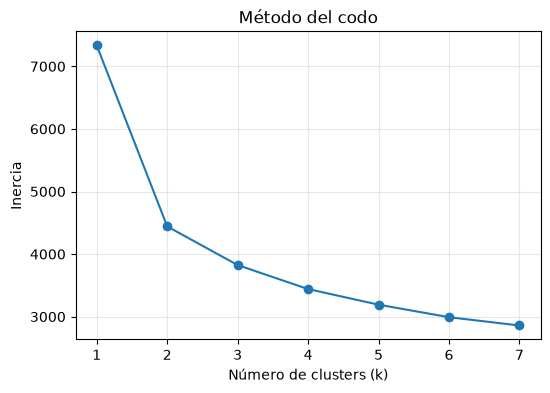

In [3]:
inercias = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_preparado)
    inercias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(range(1, 8), inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(alpha=.3)
plt.show()

In [4]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster_kmeans"] = kmeans.fit_predict(X_preparado)

sil_kmeans = silhouette_score(X_preparado, df["cluster_kmeans"])
print(f"Silhouette score K-Means (k=3): {sil_kmeans:.3f}")

print("\nPerfil promedio por cluster:")
print(df.groupby("cluster_kmeans")[variables_numericas + ["Precio arriendo"]].mean().round(1))

Silhouette score K-Means (k=3): 0.255

Perfil promedio por cluster:
                Área m²  Habitaciones  Estrato  Baños  Antig[uedad  \
cluster_kmeans                                                       
0                  61.3           1.8      3.0    1.0          8.6   
1                 154.6           4.0      5.5    1.5          8.4   
2                  60.7           1.8      3.0    2.0          8.5   

                Precio arriendo  
cluster_kmeans                   
0                     2000101.3  
1                     6300711.6  
2                     1967061.1  


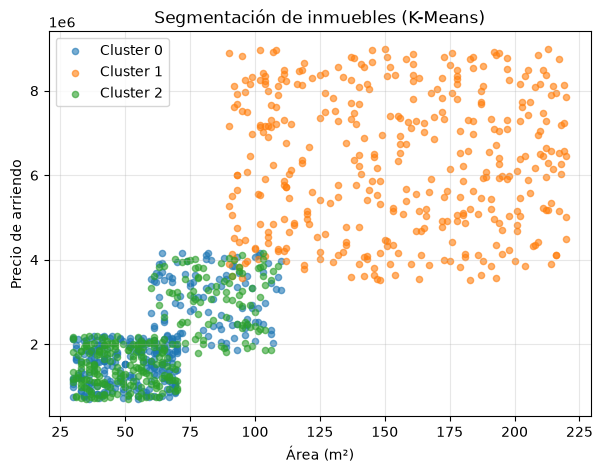

In [5]:
colores = ["#1f77b4", "#ff7f0e", "#2ca02c"]
plt.figure(figsize=(7, 5))
for c in sorted(df["cluster_kmeans"].unique()):
    subset = df[df["cluster_kmeans"] == c]
    plt.scatter(subset["Área m²"], subset["Precio arriendo"], label=f"Cluster {c}", color=colores[c], alpha=.6, s=20)
plt.xlabel("Área (m²)")
plt.ylabel("Precio de arriendo")
plt.title("Segmentación de inmuebles (K-Means)")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 4. Clustering Jerárquico

Se usa el método de Ward. Para el dendrograma se toma una muestra de 40 inmuebles, ya que 1000 hojas resultarían ilegibles.

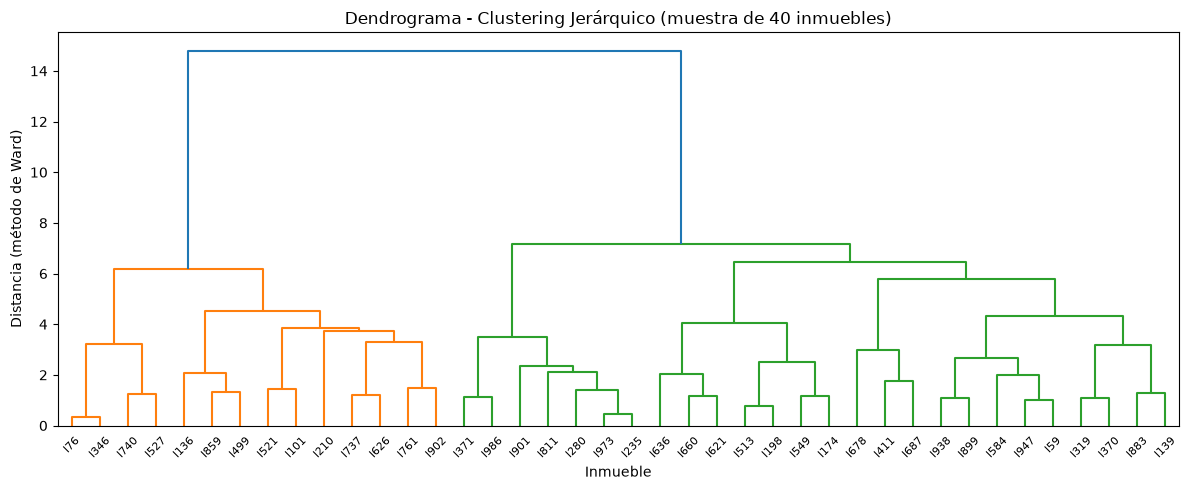

In [6]:
muestra_idx = np.random.RandomState(42).choice(len(X_preparado), size=40, replace=False)
X_muestra = X_preparado[muestra_idx]

enlace = linkage(X_muestra, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(enlace, labels=[f"I{i}" for i in muestra_idx])
plt.title("Dendrograma - Clustering Jerárquico (muestra de 40 inmuebles)")
plt.xlabel("Inmueble")
plt.ylabel("Distancia (método de Ward)")
plt.tight_layout()
plt.show()

In [7]:
jerarquico = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["cluster_jerarquico"] = jerarquico.fit_predict(X_preparado)

sil_jerarquico = silhouette_score(X_preparado, df["cluster_jerarquico"])
print(f"Silhouette score Clustering Jerárquico: {sil_jerarquico:.3f}")

coincidencia = (df["cluster_kmeans"] == df["cluster_jerarquico"]).mean()
print(f"Coincidencia de etiquetas entre K-Means y Jerárquico: {coincidencia*100:.1f}%")

Silhouette score Clustering Jerárquico: 0.219
Coincidencia de etiquetas entre K-Means y Jerárquico: 91.3%


## 5. Reducción de dimensionalidad con PCA

Varianza explicada por componente: [0.46544441 0.13748548]
Varianza acumulada: 0.602929883379633


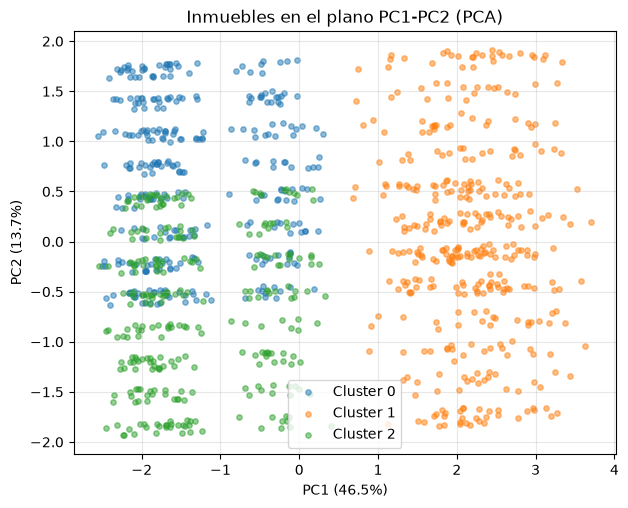

In [8]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_preparado)

print("Varianza explicada por componente:", pca.explained_variance_ratio_)
print("Varianza acumulada:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5.5))
for c in sorted(df["cluster_kmeans"].unique()):
    seleccion = df["cluster_kmeans"] == c
    plt.scatter(X_pca[seleccion, 0], X_pca[seleccion, 1], label=f"Cluster {c}", color=colores[c], alpha=.5, s=15)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Inmuebles en el plano PC1-PC2 (PCA)")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 6. Reducción de dimensionalidad con SVD

Varianza explicada por componente (SVD): [0.46544441 0.13748548]
Varianza acumulada (SVD): 0.6029298817407637


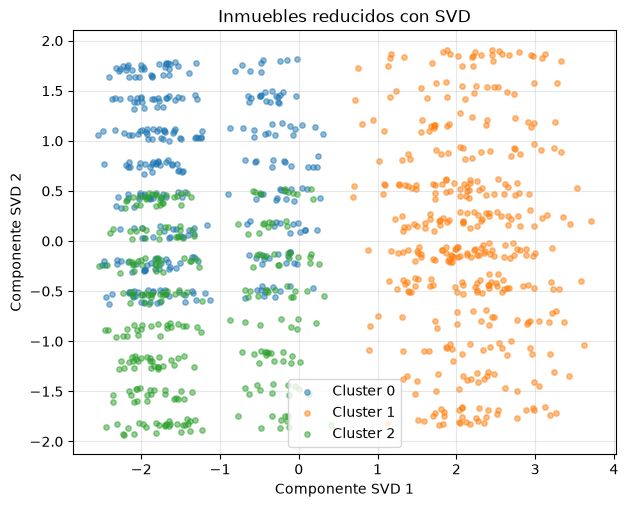

In [9]:
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd = svd.fit_transform(X_preparado)

print("Varianza explicada por componente (SVD):", svd.explained_variance_ratio_)
print("Varianza acumulada (SVD):", svd.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5.5))
for c in sorted(df["cluster_kmeans"].unique()):
    seleccion = df["cluster_kmeans"] == c
    plt.scatter(X_svd[seleccion, 0], X_svd[seleccion, 1], label=f"Cluster {c}", color=colores[c], alpha=.5, s=15)
plt.xlabel("Componente SVD 1")
plt.ylabel("Componente SVD 2")
plt.title("Inmuebles reducidos con SVD")
plt.legend()
plt.grid(alpha=.3)
plt.show()

## 7. Conclusiones

- K-Means y Clustering Jerárquico coincidieron en el 91.3% de las asignaciones, lo que confirma que los tres segmentos (económico, intermedio, premium) reflejan una estructura real del dataset y no un artefacto de un solo algoritmo.
- El silhouette score moderado (0.22-0.26) indica grupos presentes pero no perfectamente separados, consistente con la existencia de una zona de transición entre inmuebles económicos e intermedios.
- PCA y SVD produjeron resultados idénticos en este caso, porque los datos ya estaban centrados tras el escalado: sobre datos centrados, ambos métodos son matemáticamente equivalentes.
- La segmentación resultante le da a la inmobiliaria una base objetiva para diferenciar su estrategia comercial por grupo.